Name = Tanishka

Admission Number = 2026B15310089

Course = B.Tech AIML-6

Batch = Data Analyst-7

In [2]:

# Install UCI dataset library
!pip install -q ucimlrepo


In [3]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

# Fetch dataset from UCI
online_retail = fetch_ucirepo(id=352)

# Load data
df = online_retail.data.features.copy()

# Add target columns if available
if online_retail.data.targets is not None:
    df = pd.concat(
        [df, online_retail.data.targets], axis=1
    )

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

# Display first five rows
df.head()


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:

# Dataset information
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

# Dataset information
df.info()


Dataset Shape: (541909, 6)

Columns:
Index(['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID',
       'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


In [7]:
df.head(10)

,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [8]:
df.tail()

,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [10]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 6007


In [11]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [12]:
print(df.dtypes)

Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [16]:
print(df.columns.tolist())

['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [17]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(url)

print(df.shape)

(541909, 8)


In [18]:
# Create a copy of original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Convert InvoiceDate into datetime format
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"]
)

# Remove rows with missing customer ID
clean_df = clean_df.dropna(subset=["CustomerID"])

# Remove rows with missing product descriptions
clean_df = clean_df.dropna(subset=["Description"])

# Remove cancelled transactions
clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantity and price
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
]

print("Data cleaning completed!")
print("Cleaned Dataset Shape:", clean_df.shape)

Data cleaning completed!
Cleaned Dataset Shape: (392692, 8)


In [19]:
 # Calculate total sales of transaction
clean_df["TotalSales"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Display first five rows
clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [21]:
# for total revenue
total_revenue = clean_df["TotalSales"].sum()

# Count unique customers
total_customers = clean_df["CustomerID"].nunique()

# Count unique transactions
total_transactions = clean_df["InvoiceNo"].nunique()

# Count unique products
total_products = clean_df["StockCode"].nunique()

# Display results
print("Total Revenue:", round(total_revenue, 2))
print("Total Customers:", total_customers)
print("Total Transactions:", total_transactions)
print("Total Products:", total_products)

Total Revenue: 8887208.89
Total Customers: 4338
Total Transactions: 18532
Total Products: 3665


In [23]:
# Extract month and year from InvoiceDate
clean_df["Month"] = clean_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = clean_df.groupby(
    "Month"
)["TotalSales"].sum()

# Display monthly sales
print(monthly_sales)

Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalSales, dtype: float64


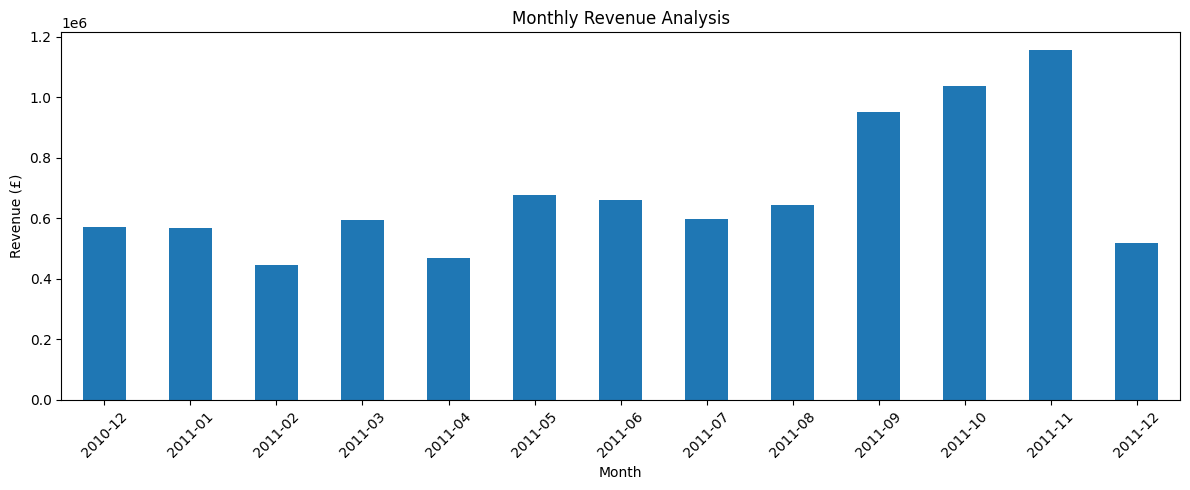

In [24]:
# Plot for monthly revenue
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

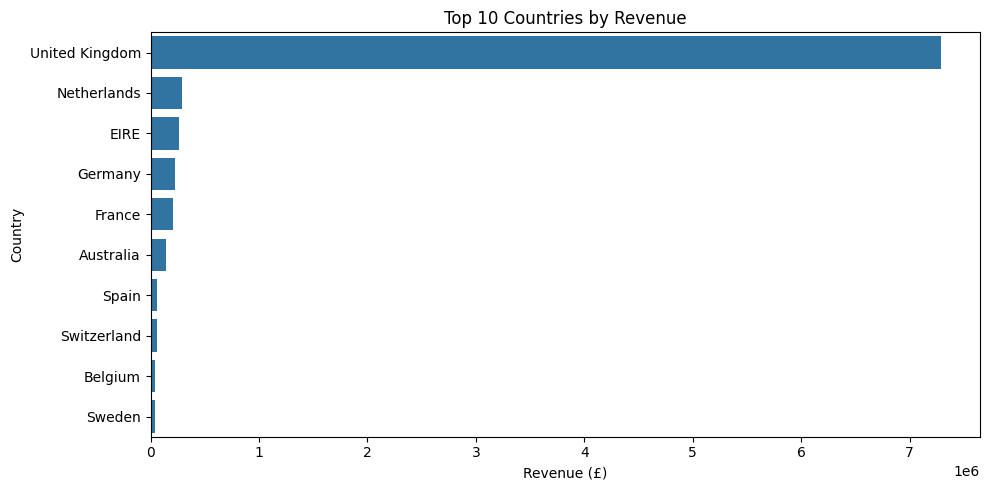

In [25]:
# Calculate revenue by country
country_sales = clean_df.groupby(
    "Country"
)["TotalSales"].sum().sort_values(ascending=False)

# for Select top 10 countries
top_countries = country_sales.head(10)

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

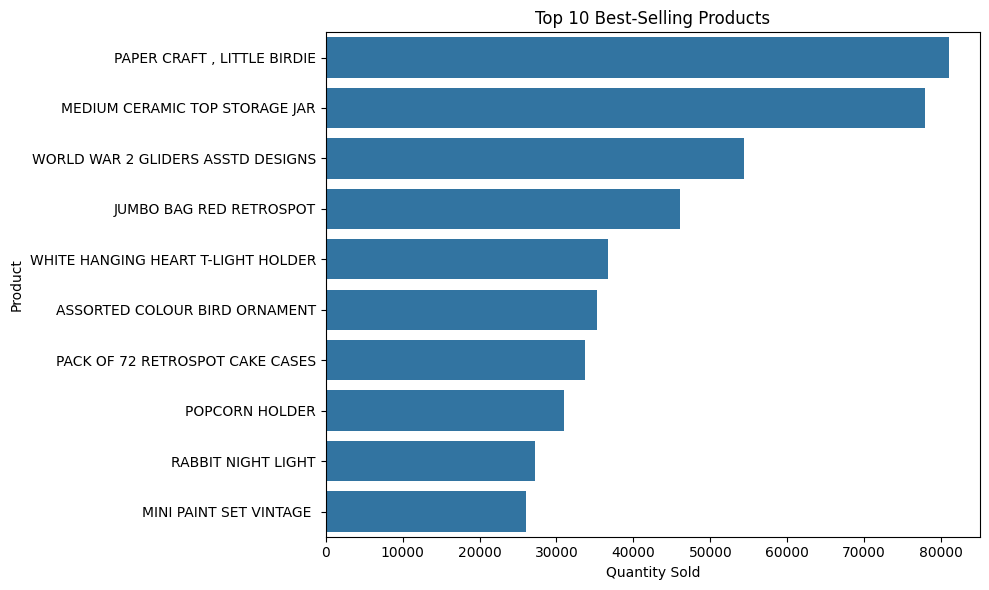

In [26]:
# Calculate quantity sold of each product
top_products = clean_df.groupby(
    "Description"
)["Quantity"].sum().sort_values(
    ascending=False
).head(10)

# Create graph
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [27]:
# Set the analysis date
analysis_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# RFM values for each customer
rfm = clean_df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (analysis_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalSales": "sum"
})

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display RFM table
print("RFM Analysis:")
rfm.head(10)

RFM Analysis:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [28]:
# to calculate RFM scores from 1 to 5

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# to Calculate total RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,7
12347.0,2,7,4310.00,5,5,5,15
12348.0,75,4,1797.24,2,4,4,10
12349.0,19,1,1757.55,4,1,4,9
12350.0,310,1,334.40,1,1,2,4
12352.0,36,8,2506.04,3,5,5,13
12353.0,204,1,89.00,1,1,1,3
12354.0,232,1,1079.40,1,1,4,6
12355.0,214,1,459.40,1,1,2,4


In [29]:
# Classifying customers into segments

def customer_segment(row):
    if row["RFM_Score"] >= 13:
        return "Best Customers"
    elif row["RFM_Score"] >= 10:
        return "Loyal Customers"
    elif row["RFM_Score"] >= 7:
        return "Potential Customers"
    else:
        return "At Risk Customers"

# Apply segmentation
rfm["Segment"] = rfm.apply(
    customer_segment,
    axis=1
)

# Display customer segments
print(rfm["Segment"].value_counts())

Segment
At Risk Customers      1312
Potential Customers    1085
Loyal Customers        1012
Best Customers          929
Name: count, dtype: int64


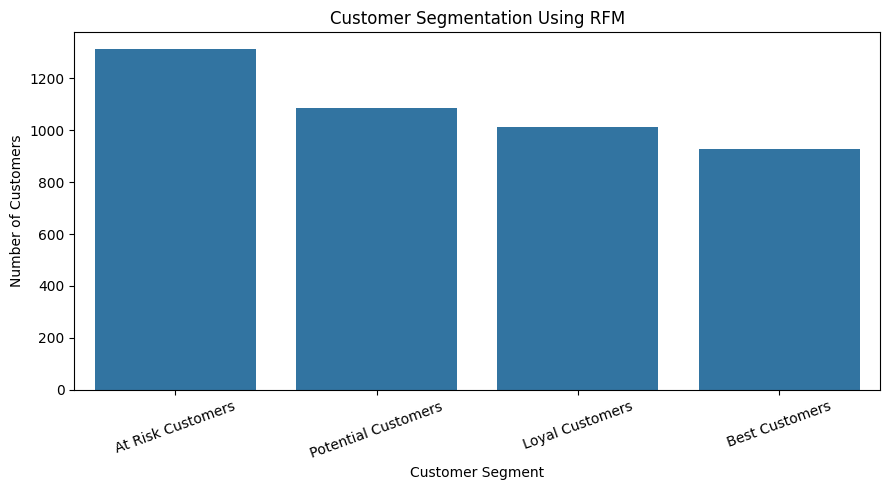

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Segmentation Using RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [31]:
# Extract month from invoice date
clean_df["InvoiceMonth"] = (
    clean_df["InvoiceDate"].dt.to_period("M")
)

clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12


In [32]:
# to Find the first purchase month of each customer
clean_df["CohortMonth"] = clean_df.groupby(
    "CustomerID"
)["InvoiceMonth"].transform("min")

clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month,InvoiceMonth,CohortMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12


In [33]:
# to Calculate cohort index
clean_df["CohortIndex"] = (
    (clean_df["InvoiceMonth"].dt.year -
     clean_df["CohortMonth"].dt.year) * 12
    +
    (clean_df["InvoiceMonth"].dt.month -
     clean_df["CohortMonth"].dt.month)
)

clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month,InvoiceMonth,CohortMonth,CohortIndex
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,2010-12,0


In [34]:
# to Count unique customers in each cohort
cohort_data = clean_df.groupby(
    ["CohortMonth", "CohortIndex"]
)["CustomerID"].nunique().reset_index()

# Create cohort table
cohort_table = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

cohort_table

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# Get the initial customer count
cohort_size = cohort_table.iloc[:, 0]

# to Calculate retention percentage
retention = cohort_table.divide(
    cohort_size,
    axis=0
) * 100

retention.round(2)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


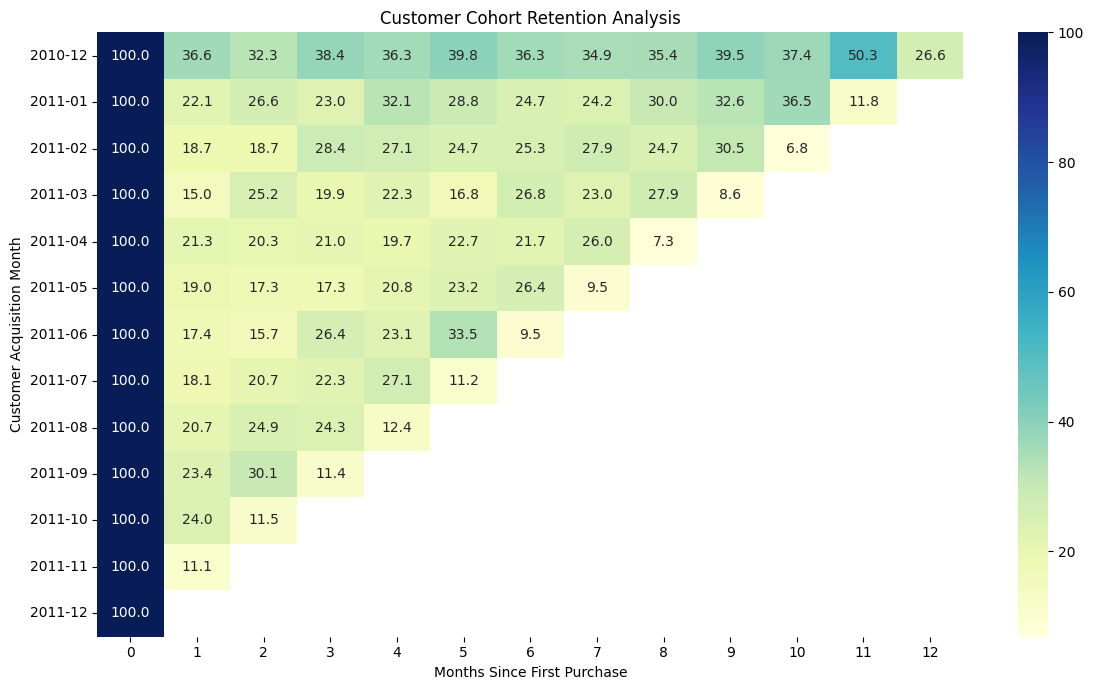

In [36]:
# To Plot cohort retention heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Customer Cohort Retention Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Month")

plt.tight_layout()
plt.show()

In [37]:
# To Calculate total observation period in months
observation_months = (
    (clean_df["InvoiceDate"].max().year -
     clean_df["InvoiceDate"].min().year) * 12
    +
    (clean_df["InvoiceDate"].max().month -
     clean_df["InvoiceDate"].min().month)
    + 1
)

print("Observation Period:", observation_months, "months")

Observation Period: 13 months


In [38]:
# Calculate total spending of each customer
customer_value = clean_df.groupby(
    "CustomerID"
)["TotalSales"].sum().to_frame()

# Calculate average monthly spending
customer_value["Monthly_Spending"] = (
    customer_value["TotalSales"] / observation_months
)

customer_value.head()

,TotalSales,Monthly_Spending
CustomerID,,
12346.0,77183.60,5937.200000
12347.0,4310.00,331.538462
12348.0,1797.24,138.249231
12349.0,1757.55,135.196154
12350.0,334.40,25.723077


In [39]:
# Assume a future period of 6 months
future_months = 6

# Estimate future spending
customer_value["Estimated_Future_Value"] = (
    customer_value["Monthly_Spending"] * future_months
)

# Calculate estimated customer lifetime value
customer_value["Estimated_CLV"] = (
    customer_value["TotalSales"] +
    customer_value["Estimated_Future_Value"]
)

customer_value.head(10)

,TotalSales,Monthly_Spending,Estimated_Future_Value,Estimated_CLV
CustomerID,,,,
12346.0,77183.60,5937.200000,35623.200000,112806.800000
12347.0,4310.00,331.538462,1989.230769,6299.230769
12348.0,1797.24,138.249231,829.495385,2626.735385
12349.0,1757.55,135.196154,811.176923,2568.726923
12350.0,334.40,25.723077,154.338462,488.738462
12352.0,2506.04,192.772308,1156.633846,3662.673846
12353.0,89.00,6.846154,41.076923,130.076923
12354.0,1079.40,83.030769,498.184615,1577.584615
12355.0,459.40,35.338462,212.030769,671.430769


In [40]:
# To Find customers with the highest estimated CLV
top_customers = customer_value.sort_values(
    by="Estimated_CLV",
    ascending=False
).head(10)

print("Top 10 Customers by Estimated CLV")
top_customers

Top 10 Customers by Estimated CLV


,TotalSales,Monthly_Spending,Estimated_Future_Value,Estimated_CLV
CustomerID,,,,
14646.0,280206.02,21554.309231,129325.855385,409531.875385
18102.0,259657.30,19973.638462,119841.830769,379499.130769
17450.0,194390.79,14953.137692,89718.826154,284109.616154
16446.0,168472.50,12959.423077,77756.538462,246229.038462
14911.0,143711.17,11054.705385,66328.232308,210039.402308
12415.0,124914.53,9608.810000,57652.860000,182567.390000
14156.0,117210.08,9016.160000,54096.960000,171307.040000
17511.0,91062.38,7004.798462,42028.790769,133091.170769
16029.0,80850.84,6219.295385,37315.772308,118166.612308


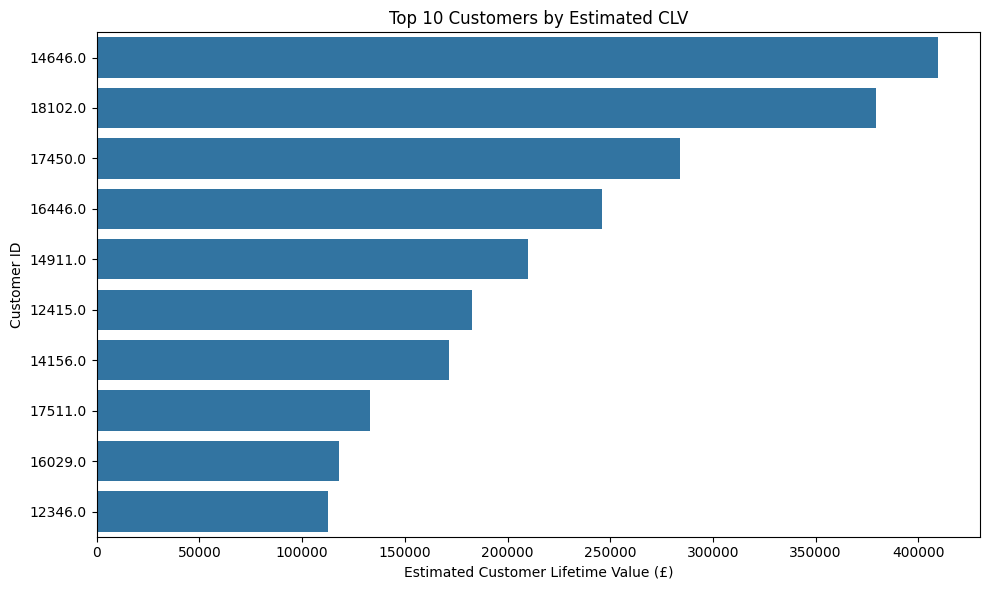

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_customers["Estimated_CLV"].values,
    y=top_customers.index.astype(str)
)

plt.title("Top 10 Customers by Estimated CLV")
plt.xlabel("Estimated Customer Lifetime Value (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [42]:
# To Compare different future periods
periods = [3, 6, 9]

sensitivity_results = {}

for months in periods:
    sensitivity_results[months] = (
        customer_value["TotalSales"] +
        customer_value["Monthly_Spending"] * months
    ).mean()

print("CLV Sensitivity Analysis")

for months, value in sensitivity_results.items():
    print(f"{months} Months: £{value:.2f}")

CLV Sensitivity Analysis
3 Months: £2521.46
6 Months: £2994.24
9 Months: £3467.01


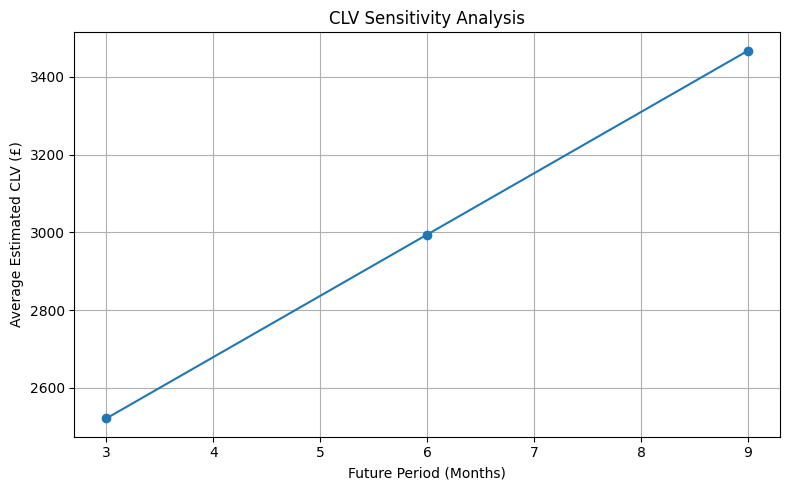

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(sensitivity_results.keys()),
    list(sensitivity_results.values()),
    marker="o"
)

plt.title("CLV Sensitivity Analysis")
plt.xlabel("Future Period (Months)")
plt.ylabel("Average Estimated CLV (£)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [44]:
# To Convert revenue into NumPy array
revenue = clean_df["TotalSales"].to_numpy()

# Calculate statistical values
average_revenue = np.mean(revenue)
median_revenue = np.median(revenue)
maximum_revenue = np.max(revenue)
minimum_revenue = np.min(revenue)
standard_deviation = np.std(revenue)

# Display results
print("Revenue Statistical Analysis")
print("Average Revenue:", round(average_revenue, 2))
print("Median Revenue:", round(median_revenue, 2))
print("Maximum Revenue:", round(maximum_revenue, 2))
print("Minimum Revenue:", round(minimum_revenue, 2))
print("Standard Deviation:", round(standard_deviation, 2))

Revenue Statistical Analysis
Average Revenue: 22.63
Median Revenue: 12.45
Maximum Revenue: 168469.6
Minimum Revenue: 0.0
Standard Deviation: 311.1


In [45]:
# To Calculate revenue percentiles
percentiles = np.percentile(
    revenue,
    [25, 50, 75, 90, 95]
)

print("Revenue Percentiles")

print("25th Percentile:", percentiles[0])
print("50th Percentile:", percentiles[1])
print("75th Percentile:", percentiles[2])
print("90th Percentile:", percentiles[3])
print("95th Percentile:", percentiles[4])

Revenue Percentiles
25th Percentile: 4.949999999999999
50th Percentile: 12.45
75th Percentile: 19.799999999999997
90th Percentile: 35.400000000000006
95th Percentile: 67.5


In [46]:
# To Find country generating maximum revenue
best_country = country_sales.idxmax()
best_country_revenue = country_sales.max()

print("Highest Revenue Country:", best_country)
print("Revenue:", round(best_country_revenue, 2))

Highest Revenue Country: United Kingdom
Revenue: 7285024.64


In [47]:
# To Find the best-selling product
best_product = top_products.idxmax()
best_product_quantity = top_products.max()

print("Best Selling Product:", best_product)
print("Quantity Sold:", best_product_quantity)

Best Selling Product: PAPER CRAFT , LITTLE BIRDIE
Quantity Sold: 80995


In [48]:
# To Find the largest customer segment
best_segment = rfm["Segment"].value_counts()

print("Customer Segment Analysis")
print(best_segment)

print("\nLargest Customer Segment:",
      best_segment.idxmax())

Customer Segment Analysis
Segment
At Risk Customers      1312
Potential Customers    1085
Loyal Customers        1012
Best Customers          929
Name: count, dtype: int64

Largest Customer Segment: At Risk Customers


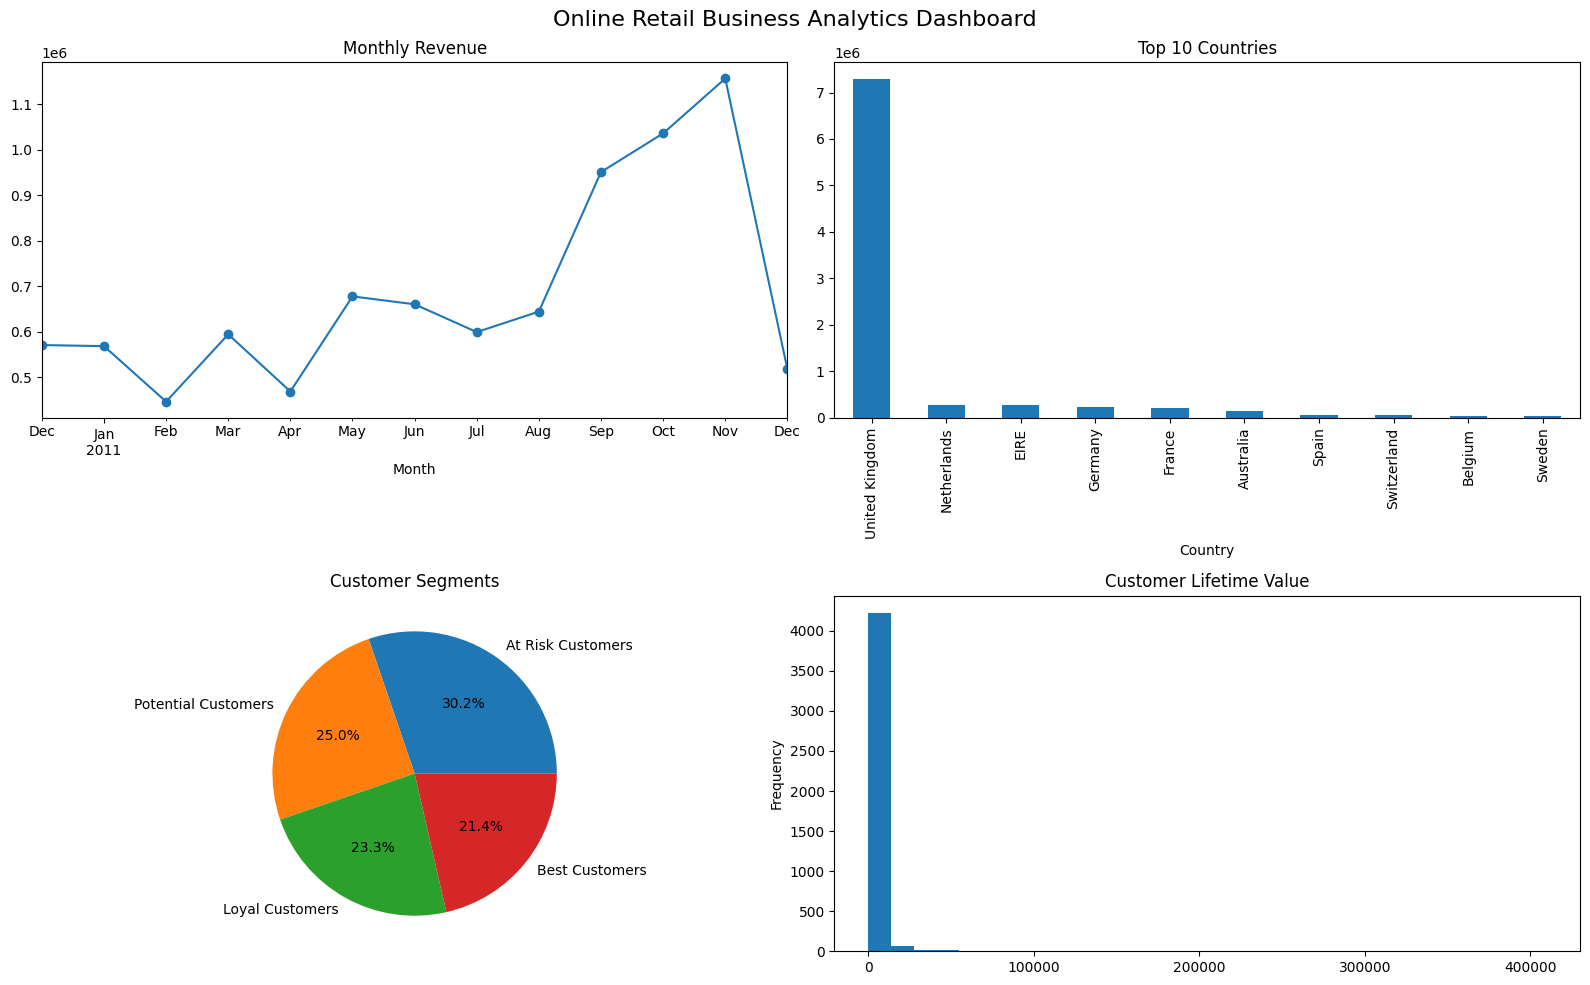

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly revenue
monthly_sales.plot(
    kind="line",
    ax=axes[0, 0],
    marker="o"
)
axes[0, 0].set_title("Monthly Revenue")

# Top countries
top_countries.plot(
    kind="bar",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 10 Countries")

# Customer segments
rfm["Segment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Customer Segments")
axes[1, 0].set_ylabel("")

# CLV distribution
customer_value["Estimated_CLV"].plot(
    kind="hist",
    bins=30,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Customer Lifetime Value")

plt.suptitle(
    "Online Retail Business Analytics Dashboard",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [50]:
clean_df.to_csv(
    "Cleaned_Online_Retail.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [51]:
rfm.to_csv(
    "Customer_RFM_Analysis.csv"
)

print("RFM analysis exported successfully!")

RFM analysis exported successfully!


In [52]:
customer_value.to_csv(
    "Customer_Lifetime_Value.csv"
)

print("CLV analysis exported successfully!")

CLV analysis exported successfully!


In [53]:
retention.to_csv(
    "Cohort_Retention_Analysis.csv"
)

print("Cohort retention exported successfully!")

Cohort retention exported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')